In [4]:
import numpy as np 
import pandas as pd
data = {
    "Order_ID": [1001, 1002, 1003, 1004, 1005,
                 1006, 1007, 1008, 1009, 1010],
    "Order_Date": [
        "2026-01-05", "2026-01-12", "2026-02-03",
        "2026-02-18", "2026-03-02", "2026-03-15",
        "2026-04-08", "2026-04-21", "2026-05-04",
        "2026-05-19"
    ],
    "Region": [
        "East", "West", "North", "East", "South",
        "West", "North", "South", "East", "West"
    ],
    "Product": [
        "Laptop", "Phone", "Tablet", "Laptop", "Phone",
        "Tablet", "Laptop", "Phone", "Tablet", "Laptop"
    ],
    "Quantity": [2, 3, 4, 1, 5, 2, 3, 4, 2, 1],
    "Unit_Price": [50000, 20000, 15000, 50000, 20000,
                   15000, 50000, 20000, 15000, 50000],
    "Unit_Cost": [40000, 15000, 10000, 42000, 16000,
                  11000, 39000, 15500, 10500, 41000]
}

df = pd.DataFrame(data)
df.head()

,Order_ID,Order_Date,Region,Product,Quantity,Unit_Price,Unit_Cost
0,1001,2026-01-05,East,Laptop,2,50000,40000
1,1002,2026-01-12,West,Phone,3,20000,15000
2,1003,2026-02-03,North,Tablet,4,15000,10000
3,1004,2026-02-18,East,Laptop,1,50000,42000
4,1005,2026-03-02,South,Phone,5,20000,16000


In [5]:
#inspecting the data:
print("the shape of the data frame:",df.shape)
print("+++++++++++++++++++++++++++++++++++++++++++")
print("Structure of the dataframe:")
df.info()
print("=============================================")
print("Checking for the null data:",df.isna().sum())
print("=============================================")
print("First 5 rows:",df.head())
print("=============================================")
print("The statistical summary of data:",df.describe())

the shape of the data frame: (10, 7)
+++++++++++++++++++++++++++++++++++++++++++
Structure of the dataframe:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Order_ID    10 non-null     int64
 1   Order_Date  10 non-null     str  
 2   Region      10 non-null     str  
 3   Product     10 non-null     str  
 4   Quantity    10 non-null     int64
 5   Unit_Price  10 non-null     int64
 6   Unit_Cost   10 non-null     int64
dtypes: int64(4), str(3)
memory usage: 692.0 bytes
Checking for the null data: Order_ID      0
Order_Date    0
Region        0
Product       0
Quantity      0
Unit_Price    0
Unit_Cost     0
dtype: int64
First 5 rows:    Order_ID  Order_Date Region Product  Quantity  Unit_Price  Unit_Cost
0      1001  2026-01-05   East  Laptop         2       50000      40000
1      1002  2026-01-12   West   Phone         3       20000      15000
2      1003  202

In [42]:
df


,Order_ID,Order_Date,Region,Product,Quantity,Unit_Price,Unit_Cost,Revenue,Profit
0,1001,2026-01-05,East,Laptop,2,50000,40000,100000,20000
1,1002,2026-01-12,West,Phone,3,20000,15000,60000,15000
2,1003,2026-02-03,North,Tablet,4,15000,10000,60000,20000
3,1004,2026-02-18,East,Laptop,1,50000,42000,50000,8000
4,1005,2026-03-02,South,Phone,5,20000,16000,100000,20000
5,1006,2026-03-15,West,Tablet,2,15000,11000,30000,8000
6,1007,2026-04-08,North,Laptop,3,50000,39000,150000,33000
7,1008,2026-04-21,South,Phone,4,20000,15500,80000,18000
8,1009,2026-05-04,East,Tablet,2,15000,10500,30000,9000
9,1010,2026-05-19,West,Laptop,1,50000,41000,50000,9000


In [6]:
#Revenue and profit :
df = pd.DataFrame(data)

df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Revenue"] = df["Quantity"] * df["Unit_Price"]
df["Profit"] = df["Quantity"] * (
    df["Unit_Price"] - df["Unit_Cost"]
)

In [7]:
#total revenue and total profit
print("Total Revenue:", df["Revenue"].sum())
print("Total Profit:", df["Profit"].sum())

Total Revenue: 710000
Total Profit: 160000


In [8]:
#analyze product performance:
product_sales = (
    df.groupby("Product").agg(
        Total_Quantity = ("Quantity","sum"),
        Total_Revenue = ("Revenue","sum"),
        Total_Profit  = ("Profit","sum")
    )
    .sort_values("Total_Revenue",ascending = False)
)
product_sales.head(1)

,Total_Quantity,Total_Revenue,Total_Profit
Product,,,
Laptop,7,350000,70000


In [9]:
#comparing revenue and profit by product
product_sales = (
    df.groupby("Product").agg(
        Total_Quantity = ("Quantity","sum"),
        Total_Revenue = ("Revenue","sum"),
        Total_Profit  = ("Profit","sum")
    )
    .sort_values("Total_Profit",ascending = False)
)
product_sales.head(1)

,Total_Quantity,Total_Revenue,Total_Profit
Product,,,
Laptop,7,350000,70000


In [10]:
# regional performance : 
region_sales = (
    df.groupby("Region")
      .agg(
          Total_Orders=("Order_ID", "count"),
          Total_Revenue=("Revenue", "sum"),
          Total_Profit=("Profit", "sum")
      )
      .sort_values("Total_Revenue", ascending=False)
)

region_sales


,Total_Orders,Total_Revenue,Total_Profit
Region,,,
North,2,210000,53000
East,3,180000,37000
South,2,180000,38000
West,3,140000,32000


In [8]:
#which region has the highest total profit, and what is that amount?
region_sales.head(1)

,Total_Orders,Total_Revenue,Total_Profit
Region,,,
North,2,210000,53000


In [11]:
#monthly sales analysis:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Order_Date"]

0   2026-01-05
1   2026-01-12
2   2026-02-03
3   2026-02-18
4   2026-03-02
5   2026-03-15
6   2026-04-08
7   2026-04-21
8   2026-05-04
9   2026-05-19
Name: Order_Date, dtype: datetime64[us]

In [12]:
#create a monthly summary:
df["Month"] = df["Order_Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Month")
      .agg(
          Total_Revenue=("Revenue", "sum"),
          Total_Profit=("Profit", "sum")
      )
)

monthly_sales
#sort values 
monthly_sales.sort_values("Total_Revenue",ascending = False).head(1)

,Total_Revenue,Total_Profit
Month,,
2026-04,230000,51000


In [11]:
# profit margin :
df["Profit_Margin"] = (
    df["Profit"] / df["Revenue"] * 100
)

df[["Product", "Revenue", "Profit", "Profit_Margin"]]

,Product,Revenue,Profit,Profit_Margin
0,Laptop,100000,20000,20.000000
1,Phone,60000,15000,25.000000
2,Tablet,60000,20000,33.333333
3,Laptop,50000,8000,16.000000
4,Phone,100000,20000,20.000000
5,Tablet,30000,8000,26.666667
6,Laptop,150000,33000,22.000000
7,Phone,80000,18000,22.500000
8,Tablet,30000,9000,30.000000
9,Laptop,50000,9000,18.000000


In [13]:
#profit margin 
product_margin = (
    df.groupby("Product")
      .agg(
          Total_Revenue=("Revenue", "sum"),
          Total_Profit=("Profit", "sum")
      )
)

product_margin["Profit_Margin"] = (
    product_margin["Total_Profit"]
    / product_margin["Total_Revenue"] * 100
)

product_margin.sort_values(
    "Profit_Margin", ascending=True
)

,Total_Revenue,Total_Profit,Profit_Margin
Product,,,
Laptop,350000,70000,20.000000
Phone,240000,53000,22.083333
Tablet,120000,37000,30.833333


In [14]:
#calculate overall business profit margin
overall_profit_margin = (
    df["Profit"].sum() / df["Revenue"].sum()
) * 100

overall_profit_margin

np.float64(22.535211267605636)

In [15]:
#regional profit margins:
region_margin = (
    df.groupby("Region")
      .agg(
          Total_Revenue=("Revenue", "sum"),
          Total_Profit=("Profit", "sum")
      )
)

region_margin["Profit_Margin"] = (
    region_margin["Total_Profit"]
    / region_margin["Total_Revenue"] * 100
)

region_margin.sort_values(
    "Profit_Margin", ascending=False
)


,Total_Revenue,Total_Profit,Profit_Margin
Region,,,
North,210000,53000,25.238095
West,140000,32000,22.857143
South,180000,38000,21.111111
East,180000,37000,20.555556


In [16]:
# find the product with the lowest profit margin in each region:
region_product = (
    df.groupby(["Region", "Product"])
      .agg(
          Total_Revenue=("Revenue", "sum"),
          Total_Profit=("Profit", "sum")
      )
)

region_product["Profit_Margin"] = (
    region_product["Total_Profit"]
    / region_product["Total_Revenue"] * 100
)



region_product.sort_values("Total_Profit",ascending = False)

region_product.sort_values(
    "Total_Profit",
    ascending=False
).head(1)


,,Total_Revenue,Total_Profit,Profit_Margin
Region,Product,,,
South,Phone,180000,38000,21.111111


In [17]:
total_revenue = df["Revenue"].sum()
total_profit = df["Profit"].sum()

overall_margin = (
    total_profit / total_revenue
) * 100

best_product = product_margin["Total_Profit"].idxmax()
highest_margin_product = product_margin["Profit_Margin"].idxmax()

best_region = region_margin["Total_Revenue"].idxmax()
highest_margin_region = region_margin["Profit_Margin"].idxmax()

print("Total Revenue:", total_revenue)
print("Total Profit:", total_profit)
print("Overall Profit Margin:", round(overall_margin, 2), "%")
print("Highest-Profit Product:", best_product)
print("Highest-Margin Product:", highest_margin_product)
print("Highest-Revenue Region:", best_region)
print("Highest-Margin Region:", highest_margin_region)

Total Revenue: 710000
Total Profit: 160000
Overall Profit Margin: 22.54 %
Highest-Profit Product: Laptop
Highest-Margin Product: Tablet
Highest-Revenue Region: North
Highest-Margin Region: North


## Project Conclusion

This retail sales analysis examined revenue, profit, product performance, regional performance, monthly trends, and profit margins using Pandas.

The dataset contained 10 synthetic orders, generating total revenue of **₹710,000** and total profit of **₹160,000**, with an overall profit margin of **22.54%**.

Laptops generated the highest total revenue and profit, while tablets had the highest profit margin at **30.83%**. The North region recorded the highest revenue and regional profit margin. The East region had the lowest regional profit margin at **20.56%**, making it a useful area for further investigation. April 2026 had the highest monthly revenue at **₹230,000**.

Based on these findings, the business could investigate costs and pricing in the East region, evaluate opportunities to grow tablet sales, and examine the factors behind April's high revenue.

Because the dataset is small and synthetic, these findings are illustrative rather than representative of a real retail business. A larger dataset would be needed to validate the patterns and support stronger business decisions.

# Three business recommendations

Recommendation 1: Investigate the East region

East has the lowest regional profit margin. Review product-level costs, pricing, and discounts to identify potential reasons for its lower profitability.




Recommendation 2: Review tablet growth opportunities

Tablets have the highest product profit margin at 30.83%. Test whether increased tablet sales could improve total profit, while monitoring demand and costs.




Recommendation 3: Investigate April's sales peak

April generated ₹230,000 in revenue. Examine the orders and business conditions behind that result before deciding whether a similar sales strategy could work in other months.


Chart	Business question
Bar chart	Which product generates the most revenue?
Bar chart	Which region generates the most profit?
Line chart	How does revenue change month by month?
Bar chart	Which product has the highest profit margin?
Scatter plot	Is there a relationship between revenue and profit?

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

product_revenue = (
    df.groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending = False)
)
product_revenue

Product
Laptop    350000
Phone     240000
Tablet    120000
Name: Revenue, dtype: int64

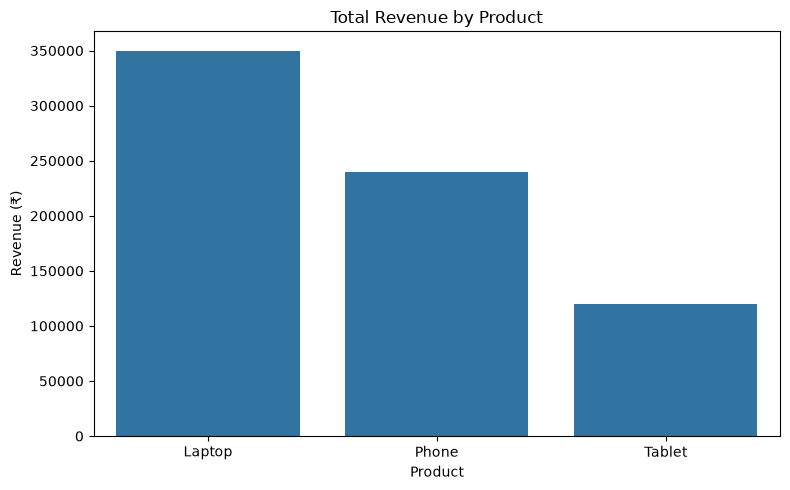

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=product_revenue.index,
    y=product_revenue.values
)

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (₹)")

plt.tight_layout()
plt.show()

### Product Revenue Insights

- Laptops generated the highest revenue at 350,000.
- Phones generated 240,000 in revenue.
- Tablets generated 120,000 in revenue.
- Laptops are the leading product by revenue in this dataset.

In [21]:
#regional profit bar chart:
region_profit = (
    df.groupby("Region")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

region_profit

Region
North    53000
South    38000
East     37000
West     32000
Name: Profit, dtype: int64

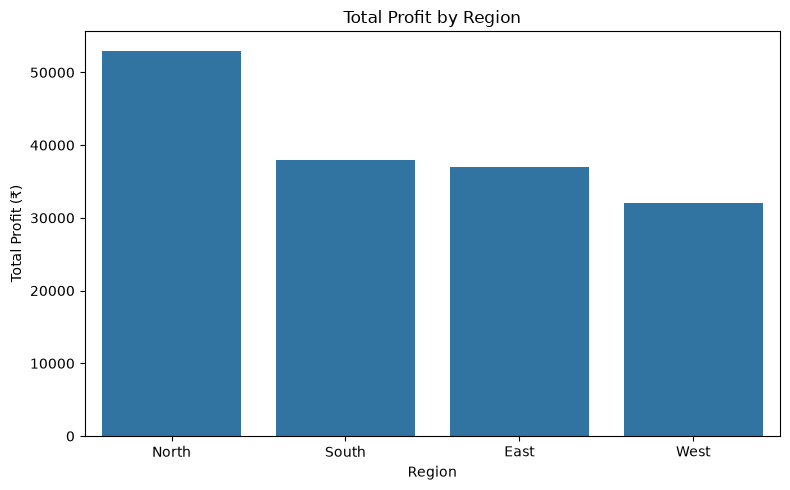

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=region_profit.index,
    y=region_profit.values
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit (₹)")

plt.tight_layout()
plt.show()

### Regional Profit Insights

- North generated the highest total profit at ₹53,000.
- South generated ₹38,000 in profit.
- East generated ₹37,000 in profit.
- West generated ₹32,000 in profit.
- Further investigation could help explain differences in regional profitability.

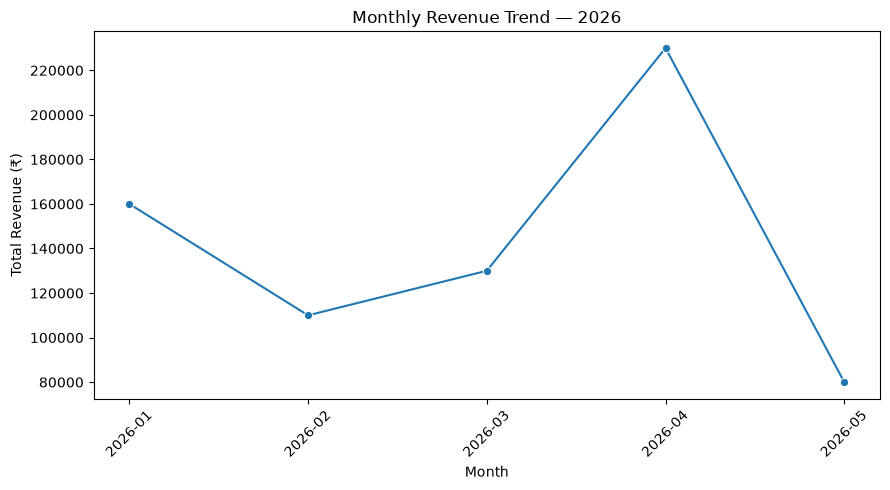

In [27]:
#montly revenue line chart:
monthly_sales

plt.figure(figsize=(9, 5))

sns.lineplot(
    x=monthly_sales.index.astype(str),
    y=monthly_sales["Total_Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend — 2026")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Revenue Insights

- April recorded the highest revenue at ₹230,000.
- May recorded the lowest revenue at ₹80,000.
- Revenue declined from January to February, rose in March and April, and fell in May.
- More data is needed to determine whether these changes represent a recurring seasonal pattern.

In [29]:
product_margin

,Total_Revenue,Total_Profit,Profit_Margin
Product,,,
Laptop,350000,70000,20.000000
Phone,240000,53000,22.083333
Tablet,120000,37000,30.833333


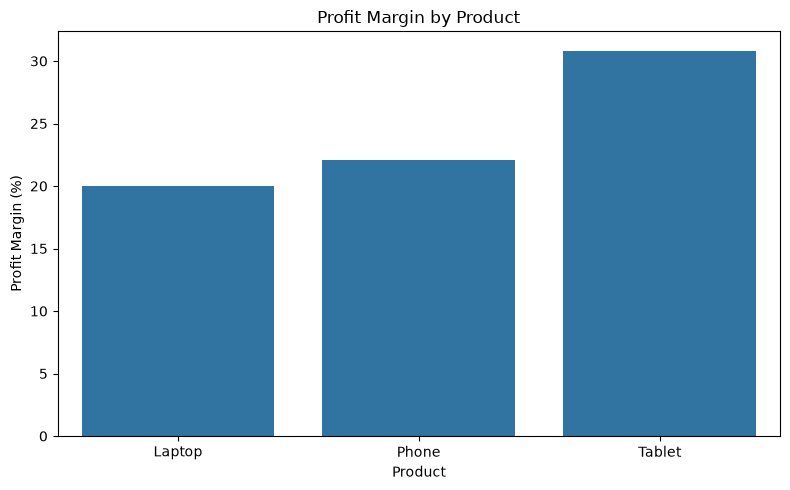

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=product_margin.index,
    y=product_margin["Profit_Margin"]
)

plt.title("Profit Margin by Product")
plt.xlabel("Product")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

### Product Profit-Margin Insights

- Tablets had the highest profit margin at 30.83%.
- Phones had a profit margin of 22.08%.
- Laptops had the lowest profit margin at 20.00%.
- Product decisions should consider both total profit and profit margin.

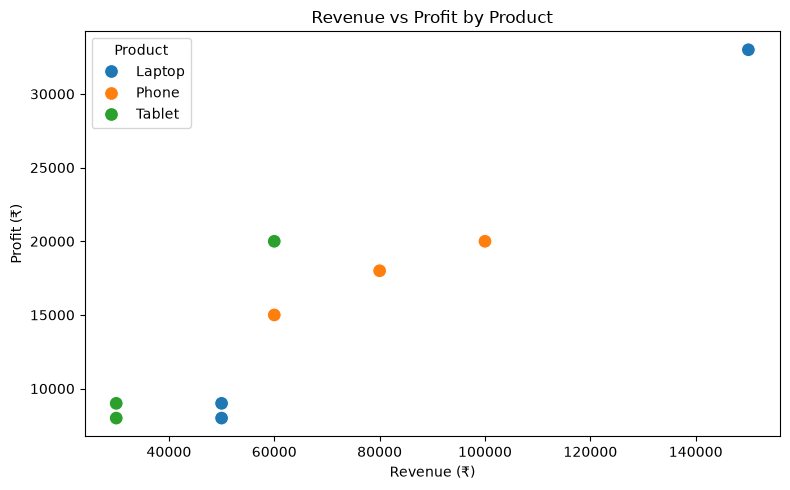

In [32]:
#Revenue vs profit scatter plot:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Revenue",
    y="Profit",
    hue="Product",
    s=100
)

plt.title("Revenue vs Profit by Product")
plt.xlabel("Revenue (₹)")
plt.ylabel("Profit (₹)")

plt.tight_layout()
plt.show()

### Revenue vs Profit Insights

- The scatter plot compares revenue and profit across individual orders.
- Orders with higher revenue may also generate higher profit, but this depends on costs and product margins.
- Product colors help compare the revenue-profit patterns of laptops, phones, and tablets.
- More observations are needed to draw reliable conclusions about the relationship.

In [33]:
print("Number of orders:", len(df))
print("Total revenue:", df["Revenue"].sum())
print("Total profit:", df["Profit"].sum())

print(
    "Overall profit margin:",
    round(df["Profit"].sum() / df["Revenue"].sum() * 100, 2),
    "%"
)

Number of orders: 10
Total revenue: 710000
Total profit: 160000
Overall profit margin: 22.54 %
